# Project 6 — Part 2a: Machine-Learning Sales Forecasting (Rossmann)

**Goal.** Predict the daily `Sales` of every Rossmann store **six weeks ahead** (a regression problem), as required by *Task 2 (2.1–2.4)* of `Project 6.pdf`.

**What this notebook does (in order)**

| Section | Content | PDF item |
|---|---|---|
| 1 | Setup, logging, loading and validating the raw CSV files | 1.2 |
| 2 | Preprocessing and feature engineering (date, holiday, month, store features) | 2.1 |
| 3 | Chronological train / validation / hold-out split (no leakage) | — |
| 4 | Loss function and evaluation metric — choice and justification | 2.3 |
| 5 | sklearn Pipelines — what each step does | 2.2 |
| 6 | Baseline, Ridge, RandomForest, HistGradientBoosting + tuning | 2.2 |
| 7 | Final comparison on the untouched 6-week hold-out | — |
| 8 | Feature importance | 2.4 |
| 9 | Prediction intervals (confidence) | 2.4 |
| 10 | Error analysis | — |
| 11 | Forecast of the real test period (`test.csv`) | — |
| 12 | Conclusions and limitations | — |

**Data used:** only the three raw files `train.csv`, `test.csv`, `store.csv` in `data/raw/`. Nothing is read from processed files or from other notebooks, so this notebook runs on its own. The raw files are never modified.

**Out of scope here (later project phase):** saving timestamped `.pkl` models (2.5), MLflow inference (2.7), the web app (Task 3) and the LSTM (2.6 — separate notebook).

## 1. Setup, logging and loading the raw data

**Why:** every later step depends on the data being what we think it is, so we first load the files with compact data types (low RAM) and run explicit checks.
Steps are logged with Python's `logging` library (PDF item 1.2).

In [7]:
import logging, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from IPython.display import display, Markdown

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer, mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import ParameterSampler
import sklearn
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)-7s | %(message)s", datefmt="%H:%M:%S", force=True)
log = logging.getLogger("rossmann.ml")
logging.getLogger("matplotlib").setLevel(logging.WARNING)

SEED = 42
N_JOBS = 2                      # a low-RAM laptop usually has 2-4 cores; change if you have more
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)

# --- plot style: one blue for the model/main series, one orange for contrast, grey for context ---
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "axes.labelsize": 10})

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "raw"
for f in ("train.csv", "test.csv", "store.csv"):
    if not (DATA_DIR / f).exists():
        raise FileNotFoundError(f"Missing {f}. Expected at: {DATA_DIR / f}")
log.info("Raw data folder: %s | scikit-learn %s | pandas %s", DATA_DIR, sklearn.__version__, pd.__version__)

22:25:40 | INFO    | Raw data folder: c:\Users\karan\OneDrive\Desktop\Intelligent Retail Sales Forecasting Using Machine Learning and Deep Learning\project_6\data\raw | scikit-learn 1.9.1 | pandas 3.1.1


In [8]:
# Compact dtypes keep RAM low (the train file has ~1 million rows).
t0 = time.time()
train = pd.read_csv(DATA_DIR / "train.csv", parse_dates=["Date"],
                    dtype={"Store": "int16", "DayOfWeek": "int8", "Sales": "int32", "Customers": "int16",
                           "Open": "int8", "Promo": "int8", "StateHoliday": "str", "SchoolHoliday": "int8"})
test = pd.read_csv(DATA_DIR / "test.csv", parse_dates=["Date"],
                   dtype={"Id": "int32", "Store": "int16", "DayOfWeek": "int8", "Open": "float32",
                          "Promo": "int8", "StateHoliday": "str", "SchoolHoliday": "int8"})
store = pd.read_csv(DATA_DIR / "store.csv")
log.info("Loaded in %.1fs | train %s | test %s | store %s | train RAM %.0f MB",
         time.time() - t0, train.shape, test.shape, store.shape, train.memory_usage(deep=True).sum() / 1e6)
display(train.head(3)); display(test.head(3)); display(store.head(3))

22:25:42 | INFO    | Loaded in 1.2s | train (1017209, 9) | test (41088, 8) | store (1115, 10) | train RAM 29 MB


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0
2,3,7,4,2015-09-17,1.0,1,0,0


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"


### 1.1 Validation checks
We check the things that could silently break a forecasting model: duplicate rows, impossible values, gaps in the calendar, and whether the test period really follows the training period.

In [9]:
checks = {}
checks["train rows / stores"] = f"{len(train):,} / {train.Store.nunique()}"
checks["train period"] = f"{train.Date.min().date()} -> {train.Date.max().date()} ({train.Date.nunique()} days)"
checks["test period"] = f"{test.Date.min().date()} -> {test.Date.max().date()} ({test.Date.nunique()} days)"
checks["test starts after train ends"] = bool(test.Date.min() > train.Date.max())
checks["duplicate (Store, Date) in train"] = int(train.duplicated(["Store", "Date"]).sum())
checks["negative sales"] = int((train.Sales < 0).sum())
checks["closed days with Sales > 0"] = int(((train.Open == 0) & (train.Sales > 0)).sum())
checks["open days with Sales == 0"] = int(((train.Open == 1) & (train.Sales == 0)).sum())
checks["DayOfWeek matches Date"] = bool((train.Date.dt.dayofweek + 1 == train.DayOfWeek).all())
checks["missing values in train"] = int(train.isna().sum().sum())
checks["missing 'Open' in test"] = int(test.Open.isna().sum())
checks["test stores not in train"] = int((~test.Store.isin(train.Store.unique())).sum())
rows_per_store = train.groupby("Store").size()
checks["stores with an incomplete calendar"] = int((rows_per_store < train.Date.nunique()).sum())
display(pd.Series(checks, name="result").to_frame())
log.info("Validation checks done")

,result
train rows / stores,"1,017,209 / 1115"
train period,2013-01-01 -> 2015-07-31 (942 days)
test period,2015-08-01 -> 2015-09-17 (48 days)
test starts after train ends,True
"duplicate (Store, Date) in train",0
negative sales,0
closed days with Sales > 0,0
open days with Sales == 0,54
DayOfWeek matches Date,True
missing values in train,0


22:25:42 | INFO    | Validation checks done


**Reading the checks.**
* The test period must start right after the training period — that is what makes this a real *forecast*.
* `Open == 1` rows with `Sales == 0` are not normal trading days; we **exclude them from training** (the metric RMSPE is also undefined for `y = 0`).
* `Open` is missing for some test rows. We **assume** such a store is open Monday–Saturday and closed on Sunday (applied in section 2). This is an **assumption, not a verified fact**; section 1.2 shows what the training history says about exactly those rows. Only a handful of rows are affected, but the assumption can be wrong for an individual store-day.
* Some stores have an incomplete calendar (rows missing). That is a property of the data and is not “repaired”: the models simply learn from the days that exist.
* **`Customers` is not available in `test.csv`**, so it cannot be a feature of a forecasting model (it would also leak the answer). We never use it as an input.

### 1.2 The missing `Open` values in `test.csv` (assumption check)
The table lists the affected test rows next to the **historic open rate of the same store on the same weekday** in `train.csv`. The rule applied later (open Mon–Sat, closed Sunday) is only an assumption; this table shows where history supports it and where it does not.

In [10]:
miss = test[test.Open.isna()][["Id", "Store", "Date", "DayOfWeek", "StateHoliday", "SchoolHoliday"]].copy()
rate = (train[train.Store.isin(miss.Store.unique())].groupby(["Store", "DayOfWeek"]).Open.mean()
        .rename("historic_open_rate_same_weekday").reset_index())
miss = miss.merge(rate, on=["Store", "DayOfWeek"], how="left")
miss["assumed_Open"] = (miss.DayOfWeek != 7).astype(int)
display(miss)
disagree = int(((miss.historic_open_rate_same_weekday >= 0.5).astype(int) != miss.assumed_Open).sum())
print(f"{len(miss)} rows = {len(miss) / len(test):.3%} of test.csv | stores: {sorted(miss.Store.unique())}")
print(f"Rows where the historic open rate (>= 50 % = 'usually open') disagrees with the assumed value: {disagree}")

,Id,Store,Date,DayOfWeek,StateHoliday,SchoolHoliday,historic_open_rate_same_weekday,assumed_Open
0,480,622,2015-09-17,4,0,0,0.940741,1
1,1336,622,2015-09-16,3,0,0,0.977778,1
2,2192,622,2015-09-15,2,0,0,0.992593,1
3,3048,622,2015-09-14,1,0,0,0.955224,1
4,4760,622,2015-09-12,6,0,0,1.000000,1
5,5616,622,2015-09-11,5,0,0,0.955556,1
6,6472,622,2015-09-10,4,0,0,0.940741,1
7,7328,622,2015-09-09,3,0,0,0.977778,1
8,8184,622,2015-09-08,2,0,0,0.992593,1
9,9040,622,2015-09-07,1,0,0,0.955224,1


11 rows = 0.027% of test.csv | stores: [np.int16(622)]
Rows where the historic open rate (>= 50 % = 'usually open') disagrees with the assumed value: 0


## 2. Preprocessing and feature engineering

**Why:** models need numeric inputs without missing values, and good features turn dates and store descriptions into signals (weekday patterns, holidays, month position, competition age, promotion rounds).

All features below use **only information known in advance** for the forecast period (calendar, promo plan, holidays, store attributes). They do **not** use any sales of the forecast period, so building them before splitting is safe.

| Group | Features |
|---|---|
| Date | `Year, Month, Day, DayOfYear, WeekOfYear, DayOfWeek, IsWeekend, IsSunday` |
| Month position | `MonthPart` = 0 beginning (day 1–10), 1 middle (11–20), 2 end (21+) |
| Holidays | `StateHoliday`, `SchoolHoliday`, `DaysToNextHoliday`, `DaysSinceLastHoliday`, `DaysToChristmas` |
| Store | `StoreType`, `Assortment`, `CompetitionDistLog`, `CompetitionOpenMonths`, `CompetitionDistMissing` |
| Promotions | `Promo`, `Promo2Active` (Promo2 running and this month is a restart month), `Promo2Weeks` |

**Note on the holiday calendar (an assumption).** `DaysToNextHoliday` and `DaysSinceLastHoliday` come from a calendar of every date on which `StateHoliday != '0'` in **both** `train.csv` and `test.csv`. For the forecast period this uses the `StateHoliday` column of `test.csv`, so we **assume the holiday calendar is known in advance** (public holidays are published long before, and the PDF names holidays as a known driver). It is a calendar input, **not a target: no `Sales` or `Customers` value enters these features** (checked by a test in the cell after the sanity checks below). Limits: the calendar only contains holidays that appear in the two files, so after the last listed holiday the next one is unknown and the feature is capped at 60 days; the same cap is used for all distances.

In [11]:
# ---------- 1) store table: missing values ----------
st = store.copy()
st["CompetitionDistMissing"] = st.CompetitionDistance.isna().astype("int8")
st["CompetitionDistance"] = st.CompetitionDistance.fillna(st.CompetitionDistance.median())   # only a few stores
st["CompetitionDistLog"] = np.log1p(st.CompetitionDistance)                                 # long right tail -> log
# Promo2 start date from (year, calendar week); stores without Promo2 get NaT
st["Promo2Start"] = pd.to_datetime(st.Promo2SinceYear.astype("Int64").astype(str) + "-01-01", errors="coerce") \
                    + pd.to_timedelta((st.Promo2SinceWeek.fillna(1) - 1) * 7, unit="D")
st["PromoInterval"] = st.PromoInterval.fillna("")
st = st[["Store", "StoreType", "Assortment", "CompetitionDistLog", "CompetitionDistMissing",
         "CompetitionOpenSinceMonth", "CompetitionOpenSinceYear", "Promo2", "Promo2Start", "PromoInterval"]]

# ---------- 2) holiday calendar: ASSUMED known in advance (taken from StateHoliday in train AND test; no Sales/Customers used) ----------
all_days = pd.concat([train[["Date", "StateHoliday"]], test[["Date", "StateHoliday"]]])
hol_days = np.sort(pd.DatetimeIndex(all_days.loc[all_days.StateHoliday != "0", "Date"].unique()).values.astype("datetime64[D]").astype("int64"))
log.info("Holiday calendar: %d distinct holiday dates (%s -> %s)", len(hol_days),
         pd.Timestamp(hol_days[0], unit="D").date(), pd.Timestamp(hol_days[-1], unit="D").date())

MONTH_ABBR = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun", 7: "Jul", 8: "Aug", 9: "Sept", 10: "Oct", 11: "Nov", 12: "Dec"}

def build_features(df):
    # Turn raw rows (train or test) into model features. Uses calendar + store info only.
    d = df.merge(st, on="Store", how="left")
    out = pd.DataFrame(index=df.index)
    dt = d["Date"]
    # --- date features ---
    out["Store"] = d["Store"].values
    out["DayOfWeek"] = d["DayOfWeek"].astype("int8").values
    out["IsWeekend"] = (d["DayOfWeek"] >= 6).astype("int8").values
    out["IsSunday"] = (d["DayOfWeek"] == 7).astype("int8").values
    out["Year"] = dt.dt.year.astype("int16").values
    out["Month"] = dt.dt.month.astype("int8").values
    out["Day"] = dt.dt.day.astype("int8").values
    out["DayOfYear"] = dt.dt.dayofyear.astype("int16").values
    out["WeekOfYear"] = dt.dt.isocalendar().week.astype("int8").values
    out["MonthPart"] = np.select([dt.dt.day <= 10, dt.dt.day <= 20], [0, 1], default=2).astype("int8")
    # --- holiday features ---
    day_no = dt.values.astype("datetime64[D]").astype("int64")
    nxt = np.searchsorted(hol_days, day_no, side="left")            # first holiday on/after today
    prv = np.searchsorted(hol_days, day_no, side="right") - 1        # last holiday on/before today
    to_next = np.where(nxt < len(hol_days), hol_days[np.minimum(nxt, len(hol_days) - 1)] - day_no, 60)
    since_last = np.where(prv >= 0, day_no - hol_days[np.maximum(prv, 0)], 60)
    out["DaysToNextHoliday"] = np.clip(to_next, 0, 60).astype("int8")
    out["DaysSinceLastHoliday"] = np.clip(since_last, 0, 60).astype("int8")
    xmas = pd.to_datetime(dt.dt.year.astype(str) + "-12-25")
    xmas = xmas.where(xmas >= dt, xmas + pd.DateOffset(years=1))
    out["DaysToChristmas"] = (xmas - dt).dt.days.astype("int16").values
    out["StateHoliday"] = d["StateHoliday"].values
    out["SchoolHoliday"] = d["SchoolHoliday"].astype("int8").values
    # --- store features ---
    out["StoreType"] = d["StoreType"].values
    out["Assortment"] = d["Assortment"].values
    out["CompetitionDistLog"] = d["CompetitionDistLog"].astype("float32").values
    out["CompetitionDistMissing"] = d["CompetitionDistMissing"].astype("int8").values
    comp_open = pd.to_datetime(dict(year=d.CompetitionOpenSinceYear.fillna(1900).astype(int),
                                    month=d.CompetitionOpenSinceMonth.fillna(1).astype(int), day=1))
    months = (dt.dt.year - comp_open.dt.year) * 12 + (dt.dt.month - comp_open.dt.month)
    months = months.where(d.CompetitionOpenSinceYear.notna(), 0)       # unknown opening date -> 0
    out["CompetitionOpenMonths"] = months.clip(lower=0, upper=120).astype("int16").values
    # --- promotions ---
    out["Promo"] = d["Promo"].astype("int8").values
    month_hit = [MONTH_ABBR[m] in iv.split(",") for m, iv in zip(dt.dt.month, d.PromoInterval)]
    started = (d.Promo2 == 1) & (dt >= d.Promo2Start)
    out["Promo2Active"] = (started & np.array(month_hit)).astype("int8").values
    out["Promo2Weeks"] = np.where(started, (dt - d.Promo2Start).dt.days // 7, 0).clip(0, 400).astype("int16")
    return out

# test: missing Open is filled by an ASSUMPTION (Mon-Sat open, Sunday closed); evidence for it is shown in section 1.2
test["Open"] = test.Open.fillna((test.DayOfWeek != 7).astype("float32")).astype("int8")

t0 = time.time()
X_all = build_features(train)
X_test = build_features(test)
y_all = train["Sales"].astype("float32")
log.info("Features built in %.1fs | X_all %s | X_test %s | RAM %.0f MB", time.time() - t0, X_all.shape, X_test.shape, X_all.memory_usage(deep=True).sum() / 1e6)
display(X_all.sample(4, random_state=SEED).T)

22:25:43 | INFO    | Holiday calendar: 38 distinct holiday dates (2013-01-01 -> 2015-08-15)
22:25:49 | INFO    | Features built in 5.7s | X_all (1017209, 23) | X_test (41088, 23) | RAM 57 MB


,76435,923026,731180,790350
Store,616,592,526,601
DayOfWeek,7,2,6,2
IsWeekend,1,0,1,0
IsSunday,1,0,0,0
Year,2015,2013,2013,2013
Month,5,3,9,7
Day,24,26,14,23
DayOfYear,144,85,257,204
WeekOfYear,21,13,37,30
MonthPart,2,2,1,2


In [12]:
# Quick logical checks of the engineered features (they must be right, not just present)
sample_day = pd.Timestamp("2014-12-24")
r = X_all[train.Date == sample_day].iloc[0]
print("2014-12-24 -> DaysToChristmas:", r.DaysToChristmas, "(expected 1) | MonthPart:", r.MonthPart, "(expected 2 = end of month)")
print("Weekend rows are Sat/Sun only:", sorted(train.loc[X_all.IsWeekend == 1, "DayOfWeek"].unique()))
print("Feature NaN count (train, test):", int(X_all.isna().sum().sum()), int(X_test.isna().sum().sum()))
print("Promo2Active share of rows:", round(float(X_all.Promo2Active.mean()), 3))

2014-12-24 -> DaysToChristmas: 1 (expected 1) | MonthPart: 2 (expected 2 = end of month)
Weekend rows are Sat/Sun only: [np.int8(6), np.int8(7)]
Feature NaN count (train, test): 0 0
Promo2Active share of rows: 0.149


In [13]:
# (a) The features must not depend on Sales or Customers: rebuild them with both columns destroyed -> result must be identical.
alt = train.copy(); alt["Sales"] = 0; alt["Customers"] = 0
identical = X_all.equals(build_features(alt)); del alt
assert identical, "features depend on Sales/Customers!"
# (b) What does the holiday calendar know about the test period?
last_hol = pd.Timestamp(hol_days[-1], unit="D")
test_hols = sorted(test.loc[test.StateHoliday != "0", "Date"].dt.date.unique())
cap_tr, cap_te = (X_all.DaysToNextHoliday == 60).mean(), (X_test.DaysToNextHoliday == 60).mean()
print("Features identical after destroying Sales/Customers:", identical)
print("Holiday dates inside the test period (from test.csv):", [str(d) for d in test_hols])
print(f"Last holiday date in the calendar: {last_hol.date()}  (test period ends {test.Date.max().date()})")
print(f"Share of rows with DaysToNextHoliday at the cap (60): train {cap_tr:.1%} | test {cap_te:.1%}")

Features identical after destroying Sales/Customers: True
Holiday dates inside the test period (from test.csv): ['2015-08-15']
Last holiday date in the calendar: 2015-08-15  (test period ends 2015-09-17)
Share of rows with DaysToNextHoliday at the cap (60): train 17.6% | test 68.8%


## 3. Chronological split (no leakage)

Sales are a **time series**: random K-fold would let the model “see the future”. We therefore split by date, using the same 6-week horizon as the real forecast:

```
 |<------------- train ------------->|<-- validation 42 d -->|<-- hold-out 42 d -->|
 2013-01-01                    ...                                         2015-07-31
```

* **Train** — fit the models.
* **Validation** (42 days) — compare models and tune. Hold-out data is never used for this.
* **Hold-out** (last 42 days) — touched **once** for the final report. Before this step the models are re-fitted on train + validation, as the real forecast would also use all available history.

Only **trading days** (`Open == 1` and `Sales > 0`) are used for training and scoring. For closed days the forecast is exactly 0.

In [14]:
last_day = train.Date.max()
hold_start = last_day - pd.Timedelta(days=41)          # last 42 days
valid_start = hold_start - pd.Timedelta(days=42)       # the 42 days before
trading = (train.Open == 1) & (train.Sales > 0)

m_train = trading & (train.Date < valid_start)
m_valid = trading & (train.Date >= valid_start) & (train.Date < hold_start)
m_hold  = trading & (train.Date >= hold_start)
m_trainvalid = trading & (train.Date < hold_start)

split = pd.DataFrame({
    "part": ["train", "validation", "hold-out"],
    "from": [train.Date.min().date(), valid_start.date(), hold_start.date()],
    "to": [(valid_start - pd.Timedelta(days=1)).date(), (hold_start - pd.Timedelta(days=1)).date(), last_day.date()],
    "trading rows": [int(m_train.sum()), int(m_valid.sum()), int(m_hold.sum())]})
display(split)
assert train.Date[m_train].max() < train.Date[m_valid].min() <= train.Date[m_valid].max() < train.Date[m_hold].min(), "split is not chronological!"
d_tr, d_va, d_ho = (set(train.Date[m].unique()) for m in (m_train, m_valid, m_hold))
assert not (d_tr & d_va) and not (d_tr & d_ho) and not (d_va & d_ho), "parts share dates!"
assert train.loc[(train.Date >= valid_start) & (train.Date < hold_start), "Date"].nunique() == 42 and train.loc[train.Date >= hold_start, "Date"].nunique() == 42
print("Split checks: parts do not share a single date | validation = 42 calendar days | hold-out = 42 calendar days")
log.info("Chronological split OK")

,part,from,to,trading rows
0,train,2013-01-01,2015-05-08,766584
1,validation,2015-05-09,2015-06-19,37472
2,hold-out,2015-06-20,2015-07-31,40282


22:25:57 | INFO    | Chronological split OK


Split checks: parts do not share a single date | validation = 42 calendar days | hold-out = 42 calendar days


## 4. Loss function and evaluation metric

We separate two things: the **loss we train with** and the **metric we report**.

### Evaluation metric — RMSPE (plus RMSE, MAE, MAPE, R²)
$$\mathrm{RMSPE}=\sqrt{\frac1n\sum_i\Big(\frac{y_i-\hat y_i}{y_i}\Big)^2}$$

* **Meaning:** the typical error *relative to the size of the day*. RMSPE = 0.10 means “usually about 10 % off”.
* **Why this one:** stores differ a lot in size, and RMSE/MAE are dominated by the big ones. RMSPE measures the **relative error of each store-day** (a 500 € miss counts a lot on a 3,000 € day and little on a 15,000 € day), so large stores no longer decide the score alone. It does **not** give every store exactly equal weight: stores with more trading days contribute more rows, and days with small actual sales weigh more than days with large sales. It is easy to explain to a store manager and is the metric of the original Kaggle competition.
* **Limitations:** it is unstable when true sales are very small (we only score trading days with `Sales > 0`), and it penalises under- and over-forecasts differently. So we also report RMSE and MAE (in €), MAPE and R².

### Training loss — squared error on `log(1 + Sales)`
* A small relative error is approximately a small error in the logarithm: $\log\hat y-\log y\approx(\hat y-y)/y$. So **minimising squared error on log-sales almost minimises RMSPE** — the training loss and the metric are aligned.
* Sales are right-skewed; the log makes the target closer to symmetric and stops a few huge days from dominating the fit.
* Squared error is supported directly by all models used here (Ridge, RandomForest, HistGradientBoosting) and is easy to interpret.
* **Known side effect:** a model trained on log-sales predicts something like the *median* in euros, so the total can be slightly low. We check this bias in section 7 instead of assuming it is zero.

In [15]:
def rmspe(y_true, y_pred):
    y_true = np.asarray(y_true, dtype="float64"); y_pred = np.asarray(y_pred, dtype="float64")
    m = y_true > 0                                   # undefined for y = 0, those days are skipped
    return float(np.sqrt(np.mean(((y_true[m] - y_pred[m]) / y_true[m]) ** 2)))

def evaluate(y_true, y_pred):
    y_true = np.asarray(y_true, dtype="float64"); y_pred = np.asarray(y_pred, dtype="float64")
    return {"RMSPE": rmspe(y_true, y_pred),
            "MAPE": float(np.mean(np.abs((y_true - y_pred) / y_true))),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "MAE": float(mean_absolute_error(y_true, y_pred)),
            "R2": float(r2_score(y_true, y_pred))}

# tiny self-test so we trust the metric: 10 % too high everywhere -> RMSPE must be 0.10
assert abs(rmspe([100, 200, 300], [110, 220, 330]) - 0.10) < 1e-9
print("RMSPE self-test passed (10 % error everywhere -> 0.10)")

RMSPE self-test passed (10 % error everywhere -> 0.10)


## 5. sklearn Pipelines (PDF item 2.2)

A **Pipeline** chains preprocessing and the model into one object. Benefits: (1) the *same* steps run in training and prediction, (2) every statistic (scaling, store averages) is learned **only from the training rows** it is fitted on — no leakage, (3) one `fit` / `predict` call.

Each model below is the same chain:

```
raw feature table
   │
   ├─ StoreStatsEncoder   learns each store's typical log-sales (overall, and by weekday × promo) from training rows only
   ├─ ColumnTransformer   numeric → StandardScaler (Ridge) or pass-through (trees);  categorical → one-hot (Ridge) or ordinal codes (trees)
   └─ Regressor           Ridge | RandomForest | HistGradientBoosting

wrapped in TransformedTargetRegressor  → trains on log(1+Sales) and converts predictions back to euros
```

**Why a `StoreStatsEncoder`?** The calendar features alone cannot say *how big a store is* — store 262 sells three times more than store 307. Store id as a number is meaningless to a model. The encoder turns the store id into its **historical average log-sales**. To stop a training row from seeing its own sales, the encoder uses **leave-one-out** averages while fitting; at prediction time it uses the full training average. Because it lives inside the pipeline, it is re-fitted only on the training rows of each fit.

In [ ]:
class StoreStatsEncoder(BaseEstimator, TransformerMixin):
    # Adds two columns learned from TRAINING rows only (y is log-sales):
    #   StoreMeanLogSales      - the store's average log-sales
    #   StoreDayPromoLogMean   - the store's average log-sales for the same weekday and promo status
    # During fit_transform the row's own value is left out (leave-one-out) so it cannot see its own target.
    def fit(self, X, y):
        d = pd.DataFrame({"Store": X["Store"].values, "DayOfWeek": X["DayOfWeek"].values,
                          "Promo": X["Promo"].values, "y": np.asarray(y, dtype="float64")})
        self.global_mean_ = d.y.mean()
        self.store_mean_ = d.groupby("Store").y.mean()
        self.store_dp_mean_ = d.groupby(["Store", "DayOfWeek", "Promo"]).y.mean()
        return self

    def transform(self, X):
        X = X.copy()
        sm = X["Store"].map(self.store_mean_).fillna(self.global_mean_)
        key = pd.MultiIndex.from_arrays([X["Store"], X["DayOfWeek"], X["Promo"]])
        dp = pd.Series(self.store_dp_mean_.reindex(key).values, index=X.index)
        X["StoreMeanLogSales"] = sm.astype("float32").values
        X["StoreDayPromoLogMean"] = dp.fillna(sm).astype("float32").values
        return X

    def fit_transform(self, X, y=None, **fit_params):
        self.fit(X, y)
        d = pd.DataFrame({"Store": X["Store"].values, "DayOfWeek": X["DayOfWeek"].values,
                          "Promo": X["Promo"].values, "y": np.asarray(y, dtype="float64")})
        g1 = d.groupby("Store").y
        n1, s1 = g1.transform("count"), g1.transform("sum")
        loo_store = ((s1 - d.y) / (n1 - 1)).where(n1 > 1, self.global_mean_)
        g2 = d.groupby(["Store", "DayOfWeek", "Promo"]).y
        n2, s2 = g2.transform("count"), g2.transform("sum")
        loo_dp = ((s2 - d.y) / (n2 - 1)).where(n2 > 1, loo_store)
        X = X.copy()
        X["StoreMeanLogSales"] = loo_store.astype("float32").values
        X["StoreDayPromoLogMean"] = loo_dp.astype("float32").values
        return X

NUM = ["CompetitionDistLog", "CompetitionOpenMonths", "Promo2Weeks", "DaysToNextHoliday", "DaysSinceLastHoliday",
       "DaysToChristmas", "Year", "Month", "Day", "DayOfYear", "WeekOfYear", "StoreMeanLogSales", "StoreDayPromoLogMean"]
BIN = ["Promo", "SchoolHoliday", "IsWeekend", "IsSunday", "Promo2Active", "CompetitionDistMissing"]
CAT = ["DayOfWeek", "MonthPart", "StateHoliday", "StoreType", "Assortment"]
MODEL_INPUT_COLS = ["Store"] + [c for c in NUM if not c.startswith("StoreMean") and c != "StoreDayPromoLogMean"] + BIN + CAT

def make_pipeline(kind, drop=(), **params):
    # kind: 'ridge' (scaled + one-hot) or 'tree' (no scaling needed, ordinal codes)
    num = [c for c in NUM if c not in drop]            # 'drop' is only used by the sensitivity check in section 11.1
    if kind == "ridge":
        prep = ColumnTransformer([("num", StandardScaler(), num), ("bin", "passthrough", BIN),
                                  ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
        reg = Ridge(alpha=params.get("alpha", 1.0))
    else:
        prep = ColumnTransformer([("num", "passthrough", num), ("bin", "passthrough", BIN),
                                  ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT)])
        if kind == "rf":
            reg = RandomForestRegressor(random_state=SEED, n_jobs=N_JOBS, **params)
        else:
            reg = HistGradientBoostingRegressor(random_state=SEED, **params)
    pipe = Pipeline([("stats", StoreStatsEncoder()), ("prep", prep), ("model", reg)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1, check_inverse=False)

# smoke test on a small sample to make sure the chain works end to end
idx = np.where(m_train)[0][:5000]
tmp = make_pipeline("tree", max_iter=10).fit(X_all.iloc[idx][MODEL_INPUT_COLS], y_all.iloc[idx])
print("pipeline smoke test OK, first predictions:", tmp.predict(X_all.iloc[idx[:3]][MODEL_INPUT_COLS]).round(0))

### 5.1 Leakage check of the `StoreStatsEncoder`
Two things must be true: (1) the store averages are learned from the **training rows only**, and (2) during fitting a row's own sales are **left out** of its own feature.

In [ ]:
enc = StoreStatsEncoder()
Xtr, ytr = X_all[m_train], np.log1p(y_all[m_train].astype("float64"))
Z = enc.fit_transform(Xtr, ytr)
s1 = ytr[Xtr.Store == 1]; i0 = Xtr.index[Xtr.Store == 1][0]
ok1 = np.isclose(enc.store_mean_.loc[1], s1.mean())                                            # (1) learned from training rows only
ok2 = np.isclose(Z.loc[i0, "StoreMeanLogSales"], (s1.sum() - ytr.loc[i0]) / (len(s1) - 1), rtol=1e-5)   # (2) own value left out
ok3 = bool(train.Date[m_train].max() < valid_start)                                            # nothing from validation / hold-out was used
print(f"store 1: mean learned from training rows only: {ok1} | leave-one-out value excludes the row itself: {ok2} | training rows end before validation starts: {ok3}")
assert ok1 and ok2 and ok3

store 1: mean learned from training rows only: True | leave-one-out value excludes the row itself: True | training rows end before validation starts: True


### 5.2 Further leakage tests of the encoder
A brute-force check of the leave-one-out values on 300 random training rows (both encoder features), recomputed by hand from the raw targets.

In [ ]:
rs = np.random.RandomState(SEED); rows = rs.choice(len(Xtr), 300, replace=False)
yv, st_, dw_, pr_ = ytr.values, Xtr.Store.values, Xtr.DayOfWeek.values, Xtr.Promo.values
bad = 0
for r in rows:
    same_store = (st_ == st_[r]); same_store[r] = False                      # leave the row itself out
    e1 = yv[same_store].mean()
    same_dp = same_store & (dw_ == dw_[r]) & (pr_ == pr_[r])
    e2 = yv[same_dp].mean() if same_dp.any() else e1
    bad += (not np.isclose(Z.iloc[r]["StoreMeanLogSales"], e1, rtol=1e-4)) + (not np.isclose(Z.iloc[r]["StoreDayPromoLogMean"], e2, rtol=1e-4))
print(f"Brute-force leave-one-out check: {bad} mismatches in {len(rows) * 2} values")
assert bad == 0

Brute-force leave-one-out check: 0 mismatches in 600 values


## 6. Models, comparison and tuning

**Why these models**
* **Baseline** — the mean sales of the same store, weekday and promo status in the training period. Any real model must beat this, otherwise it adds nothing.
* **Ridge** — a regularised linear model (needs scaling, hence `StandardScaler`, as the PDF suggests). Shows what a simple, explainable model can do.
* **RandomForest** — the algorithm suggested by the PDF; handles interactions such as promo × weekday × store type without scaling.
* **HistGradientBoosting** — a fast boosted-tree model; tests whether boosting beats bagging.

**Compute choices (low-RAM laptop):** the forest uses 60 trees and each tree sees 30 % of the rows (`max_samples=0.3`); HistGradientBoosting is naturally memory-efficient. Tuning is a small random search on the **validation window only**.

In [ ]:
results = {}          # name -> metrics on the validation window
fitted_train_only = {}

def fit_eval(name, model, mask_fit, mask_eval, store_in=None):
    t0 = time.time()
    model.fit(X_all[mask_fit][MODEL_INPUT_COLS], y_all[mask_fit])
    fit_s = time.time() - t0
    pred = model.predict(X_all[mask_eval][MODEL_INPUT_COLS])
    met = evaluate(y_all[mask_eval], pred); met["fit_seconds"] = fit_s
    log.info("%-28s RMSPE %.4f | RMSE %6.0f | fit %.0fs", name, met["RMSPE"], met["RMSE"], fit_s)
    return met, pred

# ---- baseline: mean sales of the same store x weekday x promo (training rows only) ----
def baseline_predict(mask_fit, mask_eval):
    tr = pd.DataFrame({"Store": X_all.Store[mask_fit], "DayOfWeek": X_all.DayOfWeek[mask_fit], "Promo": X_all.Promo[mask_fit], "Sales": y_all[mask_fit]})
    g_sdp = tr.groupby(["Store", "DayOfWeek", "Promo"]).Sales.mean()
    g_s = tr.groupby("Store").Sales.mean()
    ev = X_all.loc[mask_eval, ["Store", "DayOfWeek", "Promo"]]
    p = pd.Series(g_sdp.reindex(pd.MultiIndex.from_frame(ev)).values, index=ev.index)
    return p.fillna(ev.Store.map(g_s)).fillna(tr.Sales.mean()).values

pred_valid = {}
pred_valid["Baseline"] = baseline_predict(m_train, m_valid)
results["Baseline"] = {**evaluate(y_all[m_valid], pred_valid["Baseline"]), "fit_seconds": 0.0}
log.info("%-28s RMSPE %.4f", "Baseline", results["Baseline"]["RMSPE"])

for name, mdl in [("Ridge", make_pipeline("ridge", alpha=1.0)),
                  ("RandomForest", make_pipeline("rf", n_estimators=60, max_features=0.5, min_samples_leaf=5, max_depth=24, max_samples=0.3)),
                  ("HistGradientBoosting (default)", make_pipeline("hgb"))]:
    results[name], pred_valid[name] = fit_eval(name, mdl, m_train, m_valid)
    fitted_train_only[name] = mdl

15:03:52 | INFO    | Baseline                     RMSPE 0.1533


15:03:54 | INFO    | Ridge                        RMSPE 0.1436 | RMSE   1027 | fit 1s


15:04:34 | INFO    | RandomForest                 RMSPE 0.1241 | RMSE    952 | fit 40s


15:04:41 | INFO    | HistGradientBoosting (default) RMSPE 0.1253 | RMSE    924 | fit 7s


### 6.1 Tuning HistGradientBoosting (random search on the validation window)
Six random settings plus the default are compared. The score is the validation RMSPE — the hold-out is not used. Settings searched: `learning_rate`, `max_leaf_nodes`, `min_samples_leaf`, `l2_regularization` (`max_iter` is fixed at 300 to keep the run time reasonable).

In [ ]:
space = {"learning_rate": [0.05, 0.1, 0.15], "max_leaf_nodes": [31, 63, 127],
         "min_samples_leaf": [20, 50, 100], "l2_regularization": [0.0, 1.0, 10.0]}
candidates = list(ParameterSampler(space, n_iter=6, random_state=SEED))
tune_rows = []
best = {"RMSPE": results["HistGradientBoosting (default)"]["RMSPE"], "params": {}, "model": fitted_train_only["HistGradientBoosting (default)"],
        "pred": pred_valid["HistGradientBoosting (default)"]}
for i, p in enumerate(candidates, 1):
    mdl = make_pipeline("hgb", max_iter=300, **p)
    met, pr = fit_eval(f"HGB candidate {i}", mdl, m_train, m_valid)
    tune_rows.append({"candidate": i, **p, "valid_RMSPE": met["RMSPE"], "seconds": met["fit_seconds"]})
    if met["RMSPE"] < best["RMSPE"]:
        best = {"RMSPE": met["RMSPE"], "params": {"max_iter": 300, **p}, "model": mdl, "pred": pr, "metrics": met}
tune = pd.DataFrame(tune_rows).sort_values("valid_RMSPE").reset_index(drop=True)
display(tune.style.format({"valid_RMSPE": "{:.4f}", "seconds": "{:.0f}"}).hide(axis="index"))
if best["params"]:
    results["HistGradientBoosting (tuned)"] = best["metrics"]; pred_valid["HistGradientBoosting (tuned)"] = best["pred"]
    fitted_train_only["HistGradientBoosting (tuned)"] = best["model"]
BEST_HGB_PARAMS = best["params"]               # {} means the default settings won
display(Markdown(f"**Best HGB settings on validation:** `{BEST_HGB_PARAMS if BEST_HGB_PARAMS else 'default settings'}` with RMSPE **{best['RMSPE']:.4f}**."))

15:05:01 | INFO    | HGB candidate 1              RMSPE 0.1158 | RMSE    874 | fit 19s


15:05:18 | INFO    | HGB candidate 2              RMSPE 0.1212 | RMSE    895 | fit 17s


15:05:35 | INFO    | HGB candidate 3              RMSPE 0.1132 | RMSE    833 | fit 16s


15:05:56 | INFO    | HGB candidate 4              RMSPE 0.1169 | RMSE    880 | fit 21s


15:06:12 | INFO    | HGB candidate 5              RMSPE 0.1159 | RMSE    851 | fit 16s


15:06:30 | INFO    | HGB candidate 6              RMSPE 0.1217 | RMSE    908 | fit 18s


candidate,min_samples_leaf,max_leaf_nodes,learning_rate,l2_regularization,valid_RMSPE,seconds
3,50,63,0.150000,0.000000,0.1132,16
1,20,63,0.050000,1.000000,0.1158,19
5,20,31,0.150000,0.000000,0.1159,16
4,50,63,0.050000,1.000000,0.1169,21
2,20,31,0.050000,0.000000,0.1212,17
6,50,31,0.050000,1.000000,0.1217,18


**Best HGB settings on validation:** `{'max_iter': 300, 'min_samples_leaf': 50, 'max_leaf_nodes': 63, 'learning_rate': 0.15, 'l2_regularization': 0.0}` with RMSPE **0.1132**.

### 6.2 Validation-window comparison (used for model selection)

,RMSPE,MAPE,RMSE,MAE,R2,fit_seconds
HistGradientBoosting (tuned),0.1132,0.085,833,609,0.925,16
RandomForest,0.1241,0.093,952,676,0.902,40
HistGradientBoosting (default),0.1253,0.092,924,660,0.908,7
Ridge,0.1436,0.102,"1,027",730,0.886,1
Baseline,0.1533,0.109,"1,104",788,0.869,0


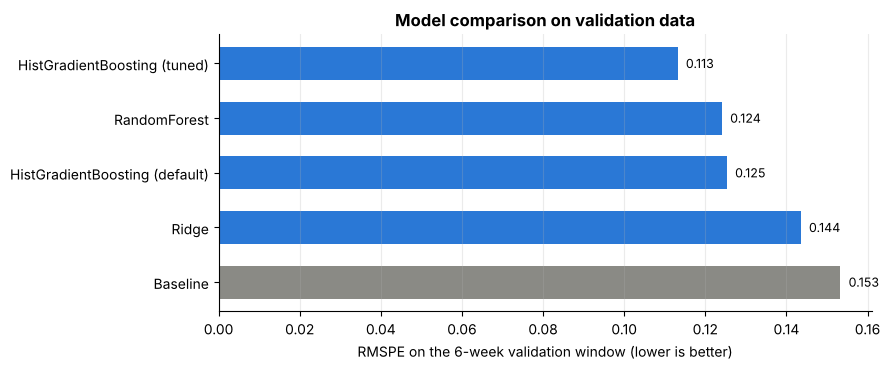

15:06:30 | INFO    | Selected on validation: HistGradientBoosting (tuned)


In [ ]:
val_tbl = pd.DataFrame(results).T[["RMSPE", "MAPE", "RMSE", "MAE", "R2", "fit_seconds"]].sort_values("RMSPE")
display(Markdown("### 6.2 Validation-window comparison (used for model selection)"))
display(val_tbl.style.format({"RMSPE": "{:.4f}", "MAPE": "{:.3f}", "RMSE": "{:,.0f}", "MAE": "{:,.0f}", "R2": "{:.3f}", "fit_seconds": "{:.0f}"}))

fig, ax = plt.subplots(figsize=(9, 3.8))
order = val_tbl.index[::-1]
bars = ax.barh(order, val_tbl.loc[order, "RMSPE"], color=[GREY if o == "Baseline" else BLUE for o in order], height=.6)
for b, v in zip(bars, val_tbl.loc[order, "RMSPE"]): ax.text(v + .002, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("RMSPE on the 6-week validation window (lower is better)"); ax.set_title("Model comparison on validation data"); ax.grid(axis="y", alpha=0)
plt.tight_layout(); plt.show()
BEST_NAME = val_tbl.drop(index="Baseline").RMSPE.idxmin()
log.info("Selected on validation: %s", BEST_NAME)

In [ ]:
rb, rm = results["Baseline"]["RMSPE"], results[BEST_NAME]["RMSPE"]
display(Markdown(f"**Selection.** The best model on the validation window is **{BEST_NAME}** (RMSPE {rm:.4f}). "
                 f"The baseline scores {rb:.4f}, so the selected model is {'**better**' if rm < rb else '**not better**'} than the baseline "
                 f"by {abs(rb - rm) / rb * 100:.1f} %. Models that do not beat the baseline are not worth deploying."))

**Selection.** The best model on the validation window is **HistGradientBoosting (tuned)** (RMSPE 0.1132). The baseline scores 0.1533, so the selected model is **better** than the baseline by 26.2 %. Models that do not beat the baseline are not worth deploying.

## 7. Final evaluation on the untouched 6-week hold-out

Now every model is **re-fitted on train + validation** (all data before the hold-out) with the settings chosen above, and scored **once** on the last 42 days. The tuned HistGradientBoosting settings from section 6.1 are reused; no further tuning happens here.

### 7.0 Leakage test of the whole workflow
A direct test that **future targets are not used**: every `Sales` value on/after the cut date is replaced by random numbers, the workflow is run again, and the predictions must be **exactly identical** (any difference would prove that something read future sales). It is done once for the model-selection fits (cut = start of validation) and once for the final fits (cut = start of the hold-out).

In [ ]:
def invariance_test(cut, mask_fit, mask_eval):
    global y_all
    original = y_all
    scrambled = original.copy(); late = (train.Date >= cut).values
    scrambled[late] = np.random.RandomState(1).uniform(1000, 40000, size=int(late.sum())).astype("float32")   # same dtype as y_all
    out = {}
    for label, make in [("baseline", None), ("Ridge", lambda: make_pipeline("ridge")), ("small HGB", lambda: make_pipeline("hgb", max_iter=30))]:
        preds = []
        for version in (original, scrambled):
            y_all = version
            if make is None:
                preds.append(baseline_predict(mask_fit, mask_eval))
            else:
                preds.append(make().fit(X_all[mask_fit][MODEL_INPUT_COLS], y_all[mask_fit]).predict(X_all[mask_eval][MODEL_INPUT_COLS]))
        out[label] = float(np.max(np.abs(preds[0] - preds[1])))
    y_all = original
    return out

inv = pd.DataFrame({"selection fits (cut = validation start)": invariance_test(valid_start, m_train, m_valid),
                    "final fits (cut = hold-out start)": invariance_test(hold_start, m_trainvalid, m_hold)})
display(inv.style.format("{:.1e}"))
assert (inv.values == 0).all() or inv.values.max() < 1e-9, "future targets influence the predictions!"
print("Max absolute difference in predictions after scrambling all future targets:", inv.values.max(), "-> no future target is used.")

NameError: name 'pd' is not defined

In [ ]:
final_specs = {
    "Ridge": lambda: make_pipeline("ridge", alpha=1.0),
    "RandomForest": lambda: make_pipeline("rf", n_estimators=60, max_features=0.5, min_samples_leaf=5, max_depth=24, max_samples=0.3),
    "HistGradientBoosting": lambda: make_pipeline("hgb", **(BEST_HGB_PARAMS or {})),
}
assert train.Date[m_trainvalid].max() < hold_start, "hold-out dates leaked into the fit!"
print("Check passed: the final fits use only days before", hold_start.date(), "(hold-out starts that day).")
hold_results, pred_hold, final_models = {}, {}, {}
pred_hold["Baseline"] = baseline_predict(m_trainvalid, m_hold)
hold_results["Baseline"] = {**evaluate(y_all[m_hold], pred_hold["Baseline"]), "fit_seconds": 0.0}
for name, mk in final_specs.items():
    mdl = mk()
    hold_results[name], pred_hold[name] = fit_eval(name + " (train+valid)", mdl, m_trainvalid, m_hold)
    final_models[name] = mdl

hold_tbl = pd.DataFrame(hold_results).T[["RMSPE", "MAPE", "RMSE", "MAE", "R2", "fit_seconds"]].sort_values("RMSPE")
display(hold_tbl.style.format({"RMSPE": "{:.4f}", "MAPE": "{:.3f}", "RMSE": "{:,.0f}", "MAE": "{:,.0f}", "R2": "{:.3f}", "fit_seconds": "{:.0f}"}))

Check passed: the final fits use only days before 2015-06-20 (hold-out starts that day).


15:06:52 | INFO    | Ridge (train+valid)          RMSPE 0.1558 | RMSE   1111 | fit 2s


15:07:37 | INFO    | RandomForest (train+valid)   RMSPE 0.1324 | RMSE   1013 | fit 45s


15:07:54 | INFO    | HistGradientBoosting (train+valid) RMSPE 0.1193 | RMSE    889 | fit 17s


,RMSPE,MAPE,RMSE,MAE,R2,fit_seconds
HistGradientBoosting,0.1193,0.087,889,594,0.915,17
RandomForest,0.1324,0.097,"1,013",676,0.890,45
Baseline,0.1468,0.108,"1,109",744,0.868,0
Ridge,0.1558,0.113,"1,111",760,0.868,2


,sum(pred) / sum(actual)
Baseline,0.9822
Ridge,1.0151
RandomForest,0.9777
HistGradientBoosting,0.9880


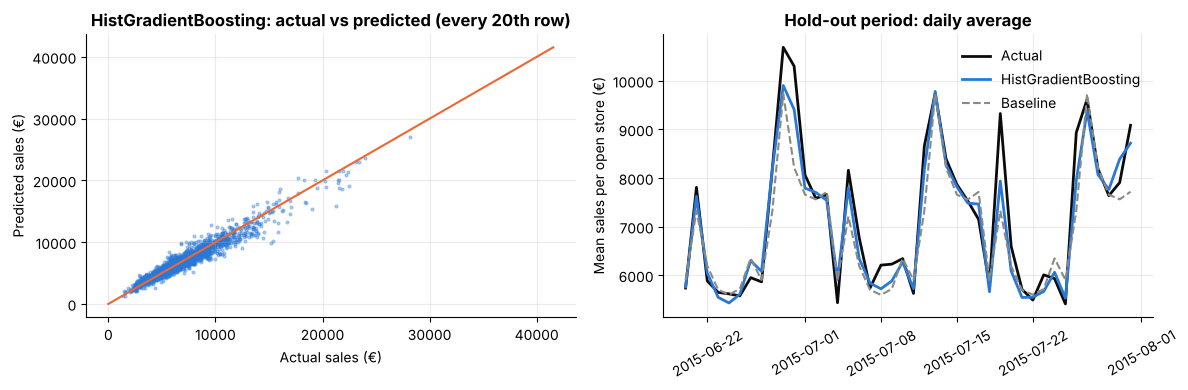

In [ ]:
# Bias check (section 4 said log-trained models may forecast slightly low): total predicted / total actual
bias = pd.Series({n: float(np.sum(p) / np.sum(y_all[m_hold])) for n, p in pred_hold.items()}, name="sum(pred) / sum(actual)").to_frame()
display(bias.style.format("{:.4f}"))

FINAL_NAME = hold_tbl.drop(index="Baseline").RMSPE.idxmin()
y_h = y_all[m_hold].values
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_h[::20], pred_hold[FINAL_NAME][::20], s=4, alpha=.35, color=BLUE)
lim = [0, max(y_h.max(), pred_hold[FINAL_NAME].max())]; axes[0].plot(lim, lim, color=ORANGE, lw=1.5)
axes[0].set_xlabel("Actual sales (€)"); axes[0].set_ylabel("Predicted sales (€)"); axes[0].set_title(f"{FINAL_NAME}: actual vs predicted (every 20th row)")
daily = pd.DataFrame({"Date": train.Date[m_hold].values, "actual": y_h, "pred": pred_hold[FINAL_NAME], "base": pred_hold["Baseline"]}).groupby("Date").mean()
axes[1].plot(daily.index, daily.actual, color="#0b0b0b", lw=2, label="Actual")
axes[1].plot(daily.index, daily.pred, color=BLUE, lw=2, label=FINAL_NAME)
axes[1].plot(daily.index, daily.base, color=GREY, lw=1.5, ls="--", label="Baseline")
axes[1].set_ylabel("Mean sales per open store (€)"); axes[1].set_title("Hold-out period: daily average"); axes[1].legend(frameon=False); axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

In [ ]:
rb, rf_, rr, rh = (hold_tbl.loc[k, "RMSPE"] for k in ("Baseline", FINAL_NAME, "Ridge", "RandomForest"))
display(Markdown(
f"**Hold-out result.** Best model: **{FINAL_NAME}** with RMSPE **{rf_:.4f}**, RMSE {hold_tbl.loc[FINAL_NAME,'RMSE']:,.0f} €, R² {hold_tbl.loc[FINAL_NAME,'R2']:.3f}. "
f"Baseline: {rb:.4f} → the best model is {'better' if rf_ < rb else 'NOT better'} than the baseline by {abs(rb - rf_) / rb * 100:.1f} %. "
f"Ridge: {rr:.4f}, RandomForest: {rh:.4f}. "
f"Selection on validation and the final hold-out agree: **{FINAL_NAME == BEST_NAME or FINAL_NAME == BEST_NAME.split(' (')[0]}**. "
f"Bias check: the best model forecasts {bias.loc[FINAL_NAME].iloc[0] * 100:.1f} % of the actual total."))

**Hold-out result.** Best model: **HistGradientBoosting** with RMSPE **0.1193**, RMSE 889 €, R² 0.915. Baseline: 0.1468 → the best model is better than the baseline by 18.7 %. Ridge: 0.1558, RandomForest: 0.1324. Selection on validation and the final hold-out agree: **True**. Bias check: the best model forecasts 98.8 % of the actual total.

## 8. Feature importance

**Method — permutation importance:** shuffle one input column at a time on hold-out rows and measure how much the error (RMSPE) gets worse. A big increase means the model relies on that column.
We measure it on the **original input columns** (not on one-hot columns), so “Store” means “knowing which store it is” (through the store statistics) and `DayOfWeek` is one item, not seven. A 20,000-row random sample of the hold-out and 3 repeats keep it fast.

In [ ]:
rng = np.random.RandomState(SEED)
hold_idx = np.where(m_hold)[0]
samp = rng.choice(hold_idx, size=20000, replace=False)
Xs, ys = X_all.iloc[samp][MODEL_INPUT_COLS], y_all.iloc[samp]
neg_rmspe = make_scorer(rmspe, greater_is_better=False)
t0 = time.time()
pi = permutation_importance(final_models[FINAL_NAME], Xs, ys, scoring=neg_rmspe, n_repeats=3, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({"feature": MODEL_INPUT_COLS, "RMSPE_increase": pi.importances_mean, "std": pi.importances_std}).sort_values("RMSPE_increase", ascending=False)
log.info("Permutation importance done in %.0fs", time.time() - t0)

top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top.feature, top.RMSPE_increase, xerr=top["std"], color=BLUE, height=.6, ecolor=GREY)
ax.set_xlabel("Increase of hold-out RMSPE when the column is shuffled"); ax.set_title(f"Feature importance — {FINAL_NAME} (top 12)"); ax.grid(axis="y", alpha=0)
plt.tight_layout(); plt.show()
display(imp.head(8).style.format({"RMSPE_increase": "{:.4f}", "std": "{:.4f}"}).hide(axis="index"))

NameError: name 'rmspe' is not defined

In [ ]:
t1, t2, t3 = imp.feature.iloc[0], imp.feature.iloc[1], imp.feature.iloc[2]
promo_rank = list(imp.feature).index("Promo") + 1
display(Markdown(
f"**Reading the chart.** The three most important inputs are **{t1}** (+{imp.RMSPE_increase.iloc[0]:.3f} RMSPE when shuffled), **{t2}** and **{t3}**. "
f"`Promo` ranks **#{promo_rank}**. Columns with an increase near zero are almost ignored by the model — "
f"for example `{imp.feature.iloc[-1]}` (change {imp.RMSPE_increase.iloc[-1]:+.4f}, i.e. practically zero). "
"Remember that importance shows what the *model uses*, not proof of cause and effect, and that correlated columns (for example `Month`, `DayOfYear`, `WeekOfYear`) share importance between them."))

**Reading the chart.** The three most important inputs are **Store** (+0.512 RMSPE when shuffled), **Promo** and **DayOfWeek**. `Promo` ranks **#2**. Columns with an increase near zero are almost ignored by the model — for example `MonthPart` (change -0.0000, i.e. practically zero). Remember that importance shows what the *model uses*, not proof of cause and effect, and that correlated columns (for example `Month`, `DayOfYear`, `WeekOfYear`) share importance between them.

## 9. Prediction intervals — how sure is the forecast? (PDF item 2.4)

A single number is not enough for planning, so we add an **interval** around each forecast.

**Method — calibrated relative residuals (split-conformal style)**
1. Take the model fitted on the **training rows only** and predict the **validation window** (data it has not seen).
2. For every trading day compute the ratio *actual ÷ predicted*. The 10 % and 90 % quantiles of this ratio (5 % and 95 % for a 90 % interval) are computed **separately for each StoreType** (different store types have different noise).
3. Interval for a new forecast *p* = [ *p* · q_low , *p* · q_high ].
4. **Check honestly:** count how often the real hold-out values fall inside the interval (coverage).

**Assumption / limitation:** the relative error in the next six weeks behaves like that of the validation weeks. It is *not* a guaranteed statistical confidence interval — holidays, new competitors or a different season can break it, which is why coverage is measured and reported.

In [ ]:
cal_model = fitted_train_only[BEST_NAME]                          # fitted on train only, never saw the validation window
ratio = y_all[m_valid].values / np.asarray(pred_valid[BEST_NAME])
stype_valid = X_all.StoreType[m_valid].values
stype_hold = X_all.StoreType[m_hold].values
LEVELS = {0.80: (0.10, 0.90), 0.90: (0.05, 0.95)}
quant = {lvl: {t: np.quantile(ratio[stype_valid == t], q) for t in np.unique(stype_valid)} for lvl, q in LEVELS.items()}

def interval(pred, stypes, lvl):
    lo = np.array([quant[lvl][t][0] for t in stypes]); hi = np.array([quant[lvl][t][1] for t in stypes])
    return pred * lo, pred * hi

p_h = pred_hold[FINAL_NAME]
cov_rows = []
for lvl in LEVELS:
    lo, hi = interval(p_h, stype_hold, lvl)
    inside = (y_h >= lo) & (y_h <= hi)
    cov_rows.append({"nominal level": lvl, "measured coverage": inside.mean(), "mean relative width": np.mean((hi - lo) / p_h)})
cov = pd.DataFrame(cov_rows)
display(cov.style.format({"nominal level": "{:.0%}", "measured coverage": "{:.1%}", "mean relative width": "{:.2f}"}).hide(axis="index"))
log.info("Interval coverage computed")

nominal level,measured coverage,mean relative width
80%,78.5%,0.27
90%,88.6%,0.36


15:08:06 | INFO    | Interval coverage computed


In [ ]:
# Plot: one example store of each store type, hold-out period, with the 80 % interval
lo80, hi80 = interval(p_h, stype_hold, 0.80)
H = pd.DataFrame({"Date": train.Date[m_hold].values, "Store": X_all.Store[m_hold].values, "StoreType": stype_hold,
                  "y": y_h, "p": p_h, "lo": lo80, "hi": hi80})
examples = [H[H.StoreType == t].Store.value_counts().index[0] for t in sorted(H.StoreType.unique())]
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True)
for ax, s in zip(axes.ravel(), examples):
    h = H[H.Store == s].sort_values("Date")
    ax.fill_between(h.Date, h.lo, h.hi, color=BLUE, alpha=.18, label="80 % interval")
    ax.plot(h.Date, h.p, color=BLUE, lw=1.8, label="Forecast"); ax.plot(h.Date, h.y, color="#0b0b0b", lw=1.2, marker="o", ms=2.5, label="Actual")
    ax.set_title(f"Store {s} (type {h.StoreType.iloc[0]})"); ax.tick_params(axis="x", rotation=30)
axes[0, 0].legend(frameon=False, fontsize=8); axes[0, 0].set_ylabel("Sales (€)"); axes[1, 0].set_ylabel("Sales (€)")
plt.suptitle("Forecast with 80 % interval on the hold-out (one store per store type)", fontweight="bold"); plt.tight_layout(); plt.show()
c80, c90 = cov.iloc[0], cov.iloc[1]
display(Markdown(f"**Result.** The nominal 80 % interval contained **{c80['measured coverage']:.1%}** of the hold-out sales (mean width ≈ {c80['mean relative width']:.0%} of the forecast); "
                 f"the nominal 90 % interval contained **{c90['measured coverage']:.1%}** (width ≈ {c90['mean relative width']:.0%}). "
                 f"Coverage {'is close to' if abs(c80['measured coverage'] - .8) < .04 else 'differs from'} the nominal level — treat the interval as a “usual range”, not a guarantee."))

NameError: name 'interval' is not defined

## 10. Error analysis — where is the model weak?
We split the hold-out RMSPE by weekday, promo status, store type and forecast week (how far ahead the day is), to learn when the forecast can be trusted less.

In [ ]:
E = pd.DataFrame({"y": y_h, "p": p_h, "DayOfWeek": X_all.DayOfWeek[m_hold].values, "Promo": X_all.Promo[m_hold].values,
                  "StoreType": stype_hold, "Date": train.Date[m_hold].values})
E["ForecastWeek"] = ((E.Date - E.Date.min()).dt.days // 7 + 1)
def by(col): return E.groupby(col).apply(lambda g: rmspe(g.y, g.p))
parts = [("DayOfWeek", "Weekday (1 = Mon … 7 = Sun)"), ("Promo", "Promo (0 = no, 1 = yes)"), ("StoreType", "Store type"), ("ForecastWeek", "Forecast week (1 = nearest)")]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
overall = rmspe(E.y, E.p)
for ax, (col, title) in zip(axes, parts):
    s = by(col); ax.bar(s.index.astype(str), s.values, color=BLUE, width=.6)
    ax.axhline(overall, color=ORANGE, lw=1.5, ls="--"); ax.set_title(title, fontsize=10); ax.grid(axis="x", alpha=0)
    for i, v in enumerate(s.values): ax.text(i, v + .003, f"{v:.3f}", ha="center", fontsize=8)
axes[0].set_ylabel("RMSPE (dashed = overall)")
plt.tight_layout(); plt.show()
worst_dow = by("DayOfWeek").idxmax(); w1, w6 = by("ForecastWeek").iloc[0], by("ForecastWeek").iloc[-1]
n_sun = int((E.DayOfWeek == 7).sum())
display(Markdown(f"**Findings.** Overall hold-out RMSPE is {overall:.4f}. The weakest weekday is **{worst_dow}** (RMSPE {by('DayOfWeek').max():.3f}"
                 f"{f', only {n_sun} trading rows because few stores open on Sundays' if worst_dow == 7 else ''}). "
                 f"Error in forecast week 1 is {w1:.3f} and in week 6 is {w6:.3f} ({(w6 / w1 - 1) * 100:+.0f} %): "
                 "The model never feeds its own forecasts back in as inputs, so errors cannot compound day by day. A rise from week 1 to week 6 is therefore more likely due to the store statistics getting older and to which weekdays/promos fall in each week (not tested here). Per-week RMSPE is also noisy because each week has only ~6,700 rows."))

NameError: name 'y_h' is not defined

## 11. Forecast of the real test period (`test.csv`, 6 weeks after the data ends)

The selected model is fitted on **all** available trading days (train + validation + hold-out) and predicts the 41,088 rows of `test.csv`. Closed days (`Open == 0`) are forecast as exactly 0. The test file has **no true sales**, so no score can be computed here — only sanity checks. (Saving this model as a timestamped file and the MLflow inference belong to the next project phase.)

In [ ]:
final_all = final_specs[FINAL_NAME]()
t0 = time.time(); final_all.fit(X_all[trading][MODEL_INPUT_COLS], y_all[trading]); log.info("Refit on all data in %.0fs", time.time() - t0)
test_pred = np.where(test.Open.values == 1, final_all.predict(X_test[MODEL_INPUT_COLS]), 0.0)
lo_t, hi_t = interval(test_pred, X_test.StoreType.values, 0.80)
fc = pd.DataFrame({"Id": test.Id, "Store": test.Store, "Date": test.Date, "Open": test.Open, "PredictedSales": test_pred.round(2),
                   "Lower80": np.where(test.Open == 1, lo_t, 0).round(2), "Upper80": np.where(test.Open == 1, hi_t, 0).round(2)})
sane = {"rows == test.csv rows": len(fc) == len(test), "Id unique": bool(fc.Id.is_unique), "no NaN": int(fc.isna().sum().sum()) == 0,
        "closed days forecast = 0": bool((fc.loc[fc.Open == 0, "PredictedSales"] == 0).all()),
        "open-day forecasts > 0": bool((fc.loc[fc.Open == 1, "PredictedSales"] > 0).all()),
        "Lower <= Prediction <= Upper (open days)": bool(((fc.Lower80 <= fc.PredictedSales) & (fc.PredictedSales <= fc.Upper80))[fc.Open == 1].all())}
display(pd.Series(sane, name="check passed").to_frame()); display(fc.head(5))
mean_open_test = fc.loc[fc.Open == 1, "PredictedSales"].mean(); mean_open_hold = float(y_h.mean())
display(Markdown(f"Mean forecast per open store-day: **{mean_open_test:,.0f} €** (last 6 weeks of actual data: {mean_open_hold:,.0f} €)."))

hist = pd.DataFrame({"Date": train.Date[trading].values, "Sales": y_all[trading].values}).groupby("Date").Sales.mean().loc[lambda s: s.index >= last_day - pd.Timedelta(days=90)]
fc_daily = fc[fc.Open == 1].groupby("Date").PredictedSales.mean()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(hist.index, hist.values, color="#0b0b0b", lw=1.5, label="Actual (last 90 days of data)")
ax.plot(fc_daily.index, fc_daily.values, color=BLUE, lw=2, label="Forecast (test period)")
ax.axvline(last_day, color=GREY, ls=":"); ax.set_ylabel("Mean sales per open store (€)"); ax.set_title("Chain-level view: history and the 6-week forecast")
ax.legend(frameon=False); ax.tick_params(axis="x", rotation=30); plt.tight_layout(); plt.show()

NameError: name 'final_specs' is not defined

### 11.1 Sensitivity check — does the holiday calendar edge matter?
Section 2 noted that the calendar knows no holiday after its last listed date, so some test rows carry the cap value (60 days) for `DaysToNextHoliday` instead of a true distance. To measure whether this can matter, the best model is re-fitted **without** the two holiday-distance columns and compared (a) on the hold-out and (b) on the test forecast.

In [ ]:
if FINAL_NAME == "HistGradientBoosting":
    HOLD = ("DaysToNextHoliday", "DaysSinceLastHoliday")
    spec = dict(BEST_HGB_PARAMS or {})
    m_a = make_pipeline("hgb", drop=HOLD, **spec).fit(X_all[m_trainvalid][MODEL_INPUT_COLS], y_all[m_trainvalid])
    r_without = rmspe(y_h, m_a.predict(X_all[m_hold][MODEL_INPUT_COLS])); r_with = hold_tbl.loc[FINAL_NAME, "RMSPE"]
    m_b = make_pipeline("hgb", drop=HOLD, **spec).fit(X_all[trading][MODEL_INPUT_COLS], y_all[trading])
    p_wo = m_b.predict(X_test[MODEL_INPUT_COLS]); is_open = (test.Open.values == 1)
    rel = np.abs(test_pred[is_open] - p_wo[is_open]) / p_wo[is_open]
    capped = (X_test.DaysToNextHoliday.values == 60)[is_open]
    display(Markdown(f"* Hold-out RMSPE with the two holiday-distance columns **{r_with:.4f}**, without **{r_without:.4f}**.\n"
                     f"* Test forecast: mean absolute difference between the two versions **{rel.mean():.2%}** over all open rows"
                     f" ({rel[capped].mean():.2%} on the {int(capped.sum()):,} rows at the cap, {rel[~capped].mean():.2%} on the other rows)."))
else:
    print("Sensitivity check is written for the HistGradientBoosting winner; the winner is", FINAL_NAME)

NameError: name 'FINAL_NAME' is not defined

## 12. Conclusions and limitations

In [ ]:
display(Markdown(f'''
**Results (all numbers come from the cells above)**
* Chronological design: train → validation (42 d) → hold-out (42 d); store statistics are learned inside the pipeline from training rows only.
* **Selected model: {FINAL_NAME}** — hold-out RMSPE **{hold_tbl.loc[FINAL_NAME, "RMSPE"]:.4f}**, RMSE {hold_tbl.loc[FINAL_NAME, "RMSE"]:,.0f} €, R² {hold_tbl.loc[FINAL_NAME, "R2"]:.3f}; baseline {hold_tbl.loc["Baseline", "RMSPE"]:.4f}.
* Most important inputs: {", ".join(imp.feature.head(3))}.
* 80 % interval coverage on the hold-out: {cov.iloc[0]["measured coverage"]:.1%}; 90 %: {cov.iloc[1]["measured coverage"]:.1%}.
'''))

NameError: name 'FINAL_NAME' is not defined

In [ ]:
import resource
print(f"Peak memory of this notebook process: {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024:,.0f} MB | CPU cores used: {N_JOBS}")

ModuleNotFoundError: No module named 'resource'

**Limitations (honest list)**
1. **One hold-out season (late June – July).** Christmas, Easter and other periods were not evaluated, so errors there may be larger.
2. **Store statistics are frozen at the end of the training data.** A store whose level changes during the six weeks (refurbishment, new competitor) is not detected.
3. **Compute budget (2 CPU cores, low RAM):** the forest is small (60 trees, 30 % of rows per tree) and was not tuned; HistGradientBoosting received only a 6-candidate random search with a fixed number of iterations. Better settings may exist.
4. **Intervals are empirical, not guaranteed:** they are calibrated on one validation window, so coverage can drift in other seasons.
5. **Closed days** are forecast as 0 from the `Open` column given in `test.csv`; the model does not predict *whether* a store opens. The few missing `Open` flags in `test.csv` are filled by the **assumption** open Mon–Sat / closed Sunday (section 1.2 shows the supporting history; it is not a verified fact).
6. **Holiday calendar assumption:** holidays of the test period are taken from `test.csv` as known in advance. The calendar knows no holiday after its last listed date, so `DaysToNextHoliday` is capped at 60 for the last weeks of the test period; section 11.1 measures how much this changes the forecast.
7. `Customers` is not forecast here (the PDF’s web app also asks for customer numbers — to be handled in the later phase, e.g. with a second model on `Customers`).

**Next in the project:** `03_Time_Series_Analysis.ipynb` (temporal behaviour) and `04_LSTM_Modeling.ipynb` (deep learning), then supporting files (timestamped models, MLflow, app).